In [ ]:
# Image Basics, Image Filters & Why We Need Convolution
# Image: skimage's built-in sample photo (no download needed).
# To use your own photo instead, replace the loading line with:
#   img = cv2.cvtColor(cv2.imread("../Datasets/my_photo.jpg"), cv2.COLOR_BGR2RGB)
#
# Needs: pip install opencv-python scikit-image matplotlib

import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

# ============================================================
# 41 - INTRODUCTION TO IMAGES
# ============================================================

# ---- 1. Load an image ----
img = data.astronaut()      # a colour photo, returned as a NumPy array

plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

# ---- 2. An image is just a NumPy array of numbers ----
print("Shape:", img.shape)       # (height, width, channels)
print("Data type:", img.dtype)   # uint8 = whole numbers from 0 to 255
print("Min / Max pixel value:", img.min(), "/", img.max())
print("Pixel at row 100, col 200 (R, G, B):", img[100, 200])

# 0 = black, 255 = full brightness. A colour image has 3 layers (channels):
# Red, Green, Blue. Every pixel is a combination of those three numbers.

# ---- 3. Look at the three colour channels separately ----
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, name in enumerate(["Red", "Green", "Blue"]):
    axes[i].imshow(img[:, :, i], cmap="gray")
    axes[i].set_title(f"{name} channel")
    axes[i].axis("off")
plt.show()

# ---- 4. Convert to grayscale (1 channel instead of 3) ----
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
print("Gray shape:", gray.shape)    # no channel dimension any more

plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")
plt.show()

# ---- 5. Resize ----
small = cv2.resize(img, (128, 128))
print("Resized shape:", small.shape)

# ---- 6. Brightness and contrast ----
# brightness = add to every pixel, contrast = multiply every pixel
# (cv2.convertScaleAbs keeps values inside 0-255 so they don't wrap around)
brighter = cv2.convertScaleAbs(img, alpha=1.0, beta=60)
higher_contrast = cv2.convertScaleAbs(img, alpha=1.8, beta=0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, title in zip(axes, [img, brighter, higher_contrast],
                          ["Original", "Brighter (+60)", "Contrast x1.8"]):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
plt.show()

# ---- 7. Histogram of pixel intensities ----
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Grayscale Histogram")
plt.xlabel("Pixel value (0 = black, 255 = white)")
plt.ylabel("Number of pixels")
plt.show()

# a histogram bunched at the left = dark image, bunched at the right = bright image


# ============================================================
# 42 - VARIOUS IMAGE FILTERS
# ============================================================
# A filter changes each pixel based on its neighbours. Smoothing filters
# remove noise, sharpening filters boost detail, edge filters pick out outlines.

# ---- 8. Add some noise so the smoothing filters have something to fix ----
np.random.seed(42)
noise = np.random.normal(0, 25, gray.shape)
noisy = np.clip(gray + noise, 0, 255).astype(np.uint8)

# ---- 9. Smoothing / blurring filters ----
avg_blur = cv2.blur(noisy, (5, 5))                 # plain average of a 5x5 neighbourhood
gauss_blur = cv2.GaussianBlur(noisy, (5, 5), 0)    # weighted average - centre counts more
median_blur = cv2.medianBlur(noisy, 5)             # median of neighbourhood - great vs speckle noise

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, im, title in zip(axes, [noisy, avg_blur, gauss_blur, median_blur],
                          ["Noisy", "Average blur", "Gaussian blur", "Median blur"]):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

# ---- 10. Sharpening filter ----
# centre pixel weighted high, neighbours subtracted -> exaggerates differences
sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])
sharpened = cv2.filter2D(gray, -1, sharpen_kernel)

# ---- 11. Edge detection filters ----
# Sobel: finds changes in brightness in one direction (x = vertical edges, y = horizontal edges)
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = np.sqrt(sobel_x ** 2 + sobel_y ** 2)

laplacian = cv2.Laplacian(gray, cv2.CV_64F)       # edges in all directions at once
canny = cv2.Canny(gray, 100, 200)                 # the cleanest, most popular edge detector

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
items = [
    (gray, "Original gray"), (sharpened, "Sharpened"), (np.abs(sobel_x), "Sobel X (vertical edges)"),
    (np.abs(sobel_y), "Sobel Y (horizontal edges)"), (sobel_combined, "Sobel combined"), (canny, "Canny edges"),
]
for ax, (im, title) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()


# ============================================================
# 43 - NEED FOR CONVOLUTION
# ============================================================
# Every filter above (blur, sharpen, Sobel) is the same operation underneath:
# slide a small grid of numbers (a "kernel") across the image, and at every
# position multiply-and-add the kernel with the pixels beneath it.
# That operation IS convolution.

# ---- 12. Convolution written by hand ----
# (plain loops so you can see exactly what happens - slow, but clear)
kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])    # this is the Sobel X kernel

gray_f = gray.astype(float)
k_h, k_w = kernel.shape
out_h = gray_f.shape[0] - k_h + 1
out_w = gray_f.shape[1] - k_w + 1
manual_output = np.zeros((out_h, out_w))

for row in range(out_h):
    for col in range(out_w):
        patch = gray_f[row:row + k_h, col:col + k_w]    # the 3x3 patch under the kernel
        manual_output[row, col] = np.sum(patch * kernel)  # multiply element-wise, then add up

# ---- 13. Check it matches OpenCV's version ----
# note: cv2.filter2D technically does cross-correlation (kernel not flipped),
# which is exactly what CNN layers also do, so the numbers should match
cv_output = cv2.filter2D(gray_f, -1, kernel)[1:-1, 1:-1]
print("Manual result matches OpenCV:", np.allclose(manual_output, cv_output))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Input")
axes[1].imshow(np.abs(manual_output), cmap="gray")
axes[1].set_title("After convolution (Sobel X kernel)")
for ax in axes:
    ax.axis("off")
plt.show()

# ---- 14. WHY do neural networks need convolution? Count the parameters ----
# Suppose we feed a 224 x 224 colour image into a layer.

h, w, c = 224, 224, 3
n_inputs = h * w * c

# Option A: fully connected (Dense) layer with 1000 neurons
dense_params = n_inputs * 1000 + 1000
# Option B: convolution layer with 64 filters of size 3x3
conv_params = (3 * 3 * c) * 64 + 64

print(f"\nInput values per image        : {n_inputs:,}")
print(f"Dense layer (1000 neurons)    : {dense_params:,} parameters")
print(f"Conv layer (64 filters, 3x3)  : {conv_params:,} parameters")
print(f"Dense layer is ~{dense_params // conv_params:,}x bigger")

# Three reasons convolution wins for images:
#   1. FAR fewer parameters  -> less memory, less overfitting
#   2. Weight sharing        -> the same kernel is reused at every position, so a
#                               pattern (say, an edge) is detected wherever it appears
#   3. Local patterns        -> nearby pixels are related; convolution looks at
#                               small neighbourhoods, a Dense layer ignores that structure
#
# In a CNN, the kernel values are not hand-picked like Sobel above - the network
# LEARNS the best kernels itself through backpropagation. That's script 44.

In [2]:
%pip install scikit-image opencv-python

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.9 MB 5.6 MB/s eta 0:00:02
   ------- -------------------------------- 2.1/11.9 MB 5.3 MB/s eta 0:00:02
   ------------ --------------------------- 3.7/11.9 MB 6.3 MB/s eta 0:00:02
   -------------------- ------------------- 6.0/11.9 MB 7.5 MB/s eta 0:00:01
   ----------------------------- ---------- 8.7/11.9 MB 8.5 MB/s eta 0:00:01
   ------------------------------------- -- 11.3/11.9 MB 9.2 MB/s eta 0:00:01
   ---------------------------------------- 11.9/11.9 MB 9.3 MB/s  0:00:01
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   --------- ------------------------------ 3.1/12.6 MB 17.2 MB/s eta 0:00:01
   ------------- -------------------------- 4.2/12.6 MB 10.4 MB/s eta 0:00:01
   ------------- -------------------------- 4.2/12.6 MB 10.4 MB/s eta 0:00:01
   ---------------- ----------------------- 5.2/12.6 MB 6.4 MB/s eta 0:00:02
   --------

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlxtend 0.25.0 requires numpy>=2.3.5, but you have numpy 2.2.6 which is incompatible.


In [3]:
# Image Basics, Image Filters & Why We Need Convolution
# Image: skimage's built-in sample photo (no download needed).
# To use your own photo instead, replace the loading line with:
#   img = cv2.cvtColor(cv2.imread("../Datasets/my_photo.jpg"), cv2.COLOR_BGR2RGB)
#
# Needs: pip install opencv-python scikit-image matplotlib

import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data


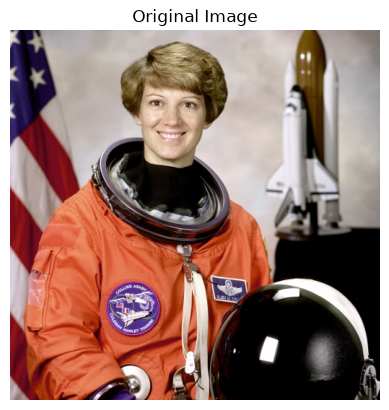

Shape: (512, 512, 3)
Data type: uint8
Min / Max pixel value: 0 / 255
Pixel at row 100, col 200 (R, G, B): [81 57 17]


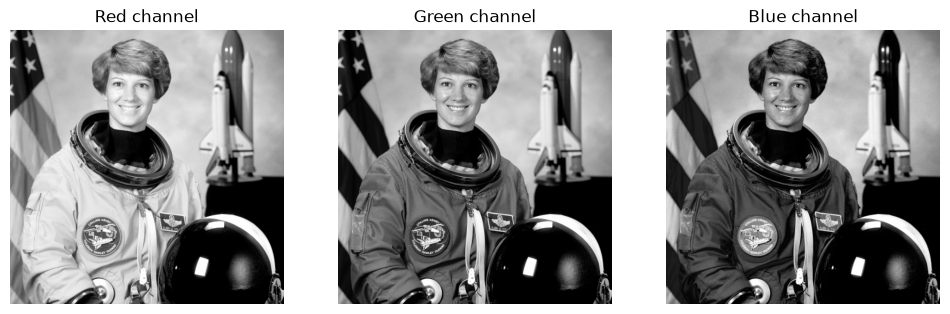

Gray shape: (512, 512)


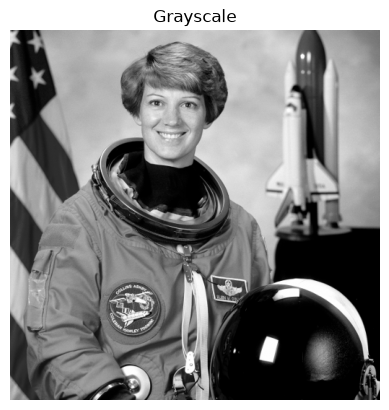

In [4]:
# ============================================================
# 41 - INTRODUCTION TO IMAGES
# ============================================================

# ---- 1. Load an image ----
img = data.astronaut()      # a colour photo, returned as a NumPy array

plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

# ---- 2. An image is just a NumPy array of numbers ----
print("Shape:", img.shape)       # (height, width, channels)
print("Data type:", img.dtype)   # uint8 = whole numbers from 0 to 255
print("Min / Max pixel value:", img.min(), "/", img.max())
print("Pixel at row 100, col 200 (R, G, B):", img[100, 200])

# 0 = black, 255 = full brightness. A colour image has 3 layers (channels):
# Red, Green, Blue. Every pixel is a combination of those three numbers.

# ---- 3. Look at the three colour channels separately ----
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, name in enumerate(["Red", "Green", "Blue"]):
    axes[i].imshow(img[:, :, i], cmap="gray")
    axes[i].set_title(f"{name} channel")
    axes[i].axis("off")
plt.show()

# ---- 4. Convert to grayscale (1 channel instead of 3) ----
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
print("Gray shape:", gray.shape)    # no channel dimension any more

plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")
plt.show()


In [ ]:
# ---- 5. Resize ----
small = cv2.resize(img, (128, 128))
print("Resized shape:", small.shape)

# ---- 6. Brightness and contrast ----
# brightness = add to every pixel, contrast = multiply every pixel
# (cv2.convertScaleAbs keeps values inside 0-255 so they don't wrap around)
brighter = cv2.convertScaleAbs(img, alpha=1.0, beta=60)
higher_contrast = cv2.convertScaleAbs(img, alpha=1.8, beta=0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, title in zip(axes, [img, brighter, higher_contrast],
                          ["Original", "Brighter (+60)", "Contrast x1.8"]):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
plt.show()

# ---- 7. Histogram of pixel intensities ----
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Grayscale Histogram")
plt.xlabel("Pixel value (0 = black, 255 = white)")
plt.ylabel("Number of pixels")
plt.show()

# a histogram bunched at the left = dark image, bunched at the right = bright image


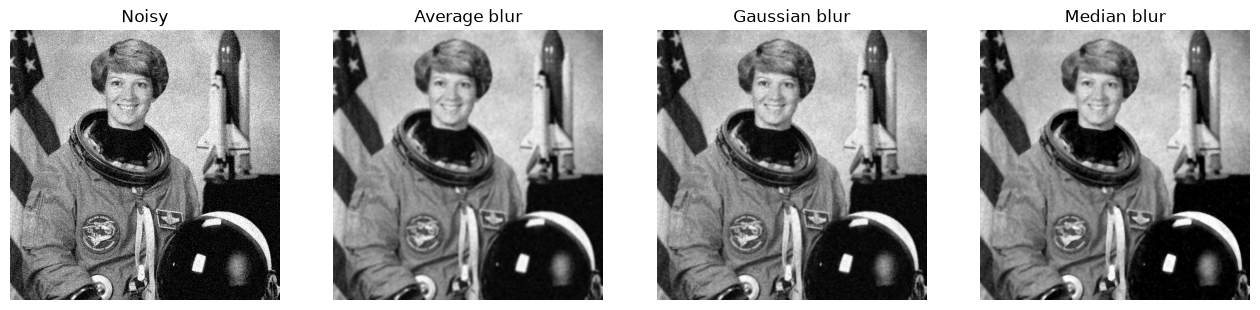

In [5]:
# a histogram bunched at the left = dark image, bunched at the right = bright image


# ============================================================
# 42 - VARIOUS IMAGE FILTERS
# ============================================================
# A filter changes each pixel based on its neighbours. Smoothing filters
# remove noise, sharpening filters boost detail, edge filters pick out outlines.

# ---- 8. Add some noise so the smoothing filters have something to fix ----
np.random.seed(42)
noise = np.random.normal(0, 25, gray.shape)
noisy = np.clip(gray + noise, 0, 255).astype(np.uint8)

# ---- 9. Smoothing / blurring filters ----
avg_blur = cv2.blur(noisy, (5, 5))                 # plain average of a 5x5 neighbourhood
gauss_blur = cv2.GaussianBlur(noisy, (5, 5), 0)    # weighted average - centre counts more
median_blur = cv2.medianBlur(noisy, 5)             # median of neighbourhood - great vs speckle noise

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, im, title in zip(axes, [noisy, avg_blur, gauss_blur, median_blur],
                          ["Noisy", "Average blur", "Gaussian blur", "Median blur"]):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()


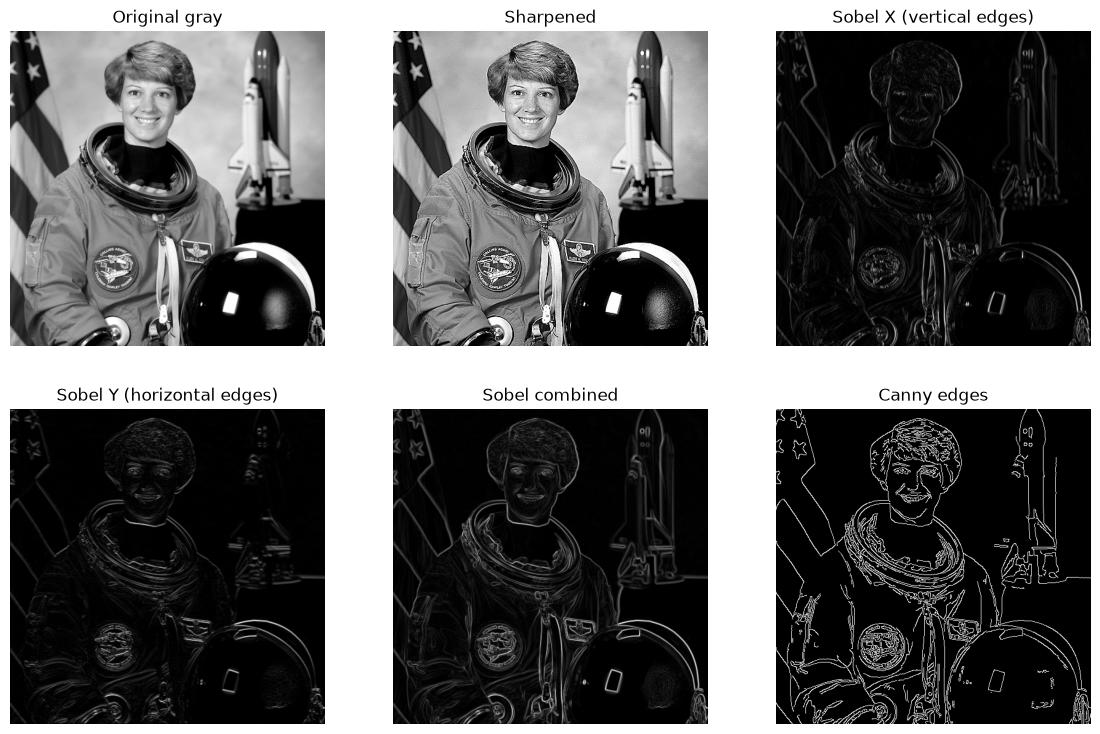

In [6]:
# ---- 10. Sharpening filter ----
# centre pixel weighted high, neighbours subtracted -> exaggerates differences
sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])
sharpened = cv2.filter2D(gray, -1, sharpen_kernel)

# ---- 11. Edge detection filters ----
# Sobel: finds changes in brightness in one direction (x = vertical edges, y = horizontal edges)
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = np.sqrt(sobel_x ** 2 + sobel_y ** 2)

laplacian = cv2.Laplacian(gray, cv2.CV_64F)       # edges in all directions at once
canny = cv2.Canny(gray, 100, 200)                 # the cleanest, most popular edge detector

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
items = [
    (gray, "Original gray"), (sharpened, "Sharpened"), (np.abs(sobel_x), "Sobel X (vertical edges)"),
    (np.abs(sobel_y), "Sobel Y (horizontal edges)"), (sobel_combined, "Sobel combined"), (canny, "Canny edges"),
]
for ax, (im, title) in zip(axes.ravel(), items):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()


In [8]:
# ============================================================
# 43 - NEED FOR CONVOLUTION
# ============================================================
# Every filter above (blur, sharpen, Sobel) is the same operation underneath:
# slide a small grid of numbers (a "kernel") across the image, and at every
# position multiply-and-add the kernel with the pixels beneath it.
# That operation IS convolution.

# ---- 12. Convolution written by hand ----
# (plain loops so you can see exactly what happens - slow, but clear)
kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])    # this is the Sobel X kernel

gray_f = gray.astype(float)
k_h, k_w = kernel.shape
out_h = gray_f.shape[0] - k_h + 1
out_w = gray_f.shape[1] - k_w + 1
manual_output = np.zeros((out_h, out_w))

for row in range(out_h):
    for col in range(out_w):
        patch = gray_f[row:row + k_h, col:col + k_w]    # the 3x3 patch under the kernel
        manual_output[row, col] = np.sum(patch * kernel)  # multiply element-wise, then add up


Manual result matches OpenCV: True


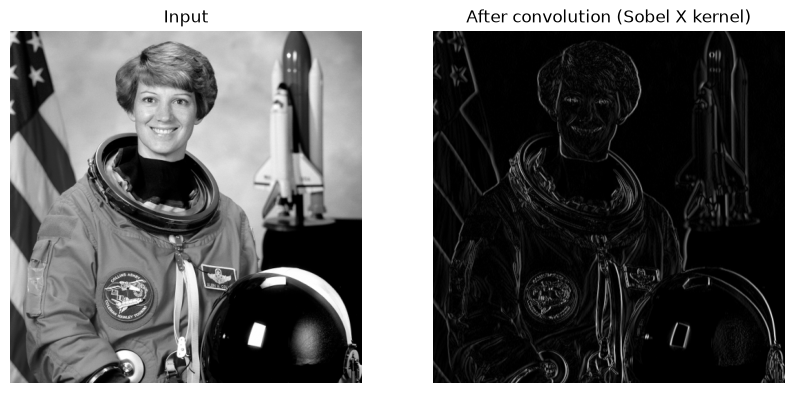


Input values per image        : 150,528
Dense layer (1000 neurons)    : 150,529,000 parameters
Conv layer (64 filters, 3x3)  : 1,792 parameters
Dense layer is ~84,000x bigger


In [9]:
# ---- 13. Check it matches OpenCV's version ----
# note: cv2.filter2D technically does cross-correlation (kernel not flipped),
# which is exactly what CNN layers also do, so the numbers should match
cv_output = cv2.filter2D(gray_f, -1, kernel)[1:-1, 1:-1]
print("Manual result matches OpenCV:", np.allclose(manual_output, cv_output))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Input")
axes[1].imshow(np.abs(manual_output), cmap="gray")
axes[1].set_title("After convolution (Sobel X kernel)")
for ax in axes:
    ax.axis("off")
plt.show()

# ---- 14. WHY do neural networks need convolution? Count the parameters ----
# Suppose we feed a 224 x 224 colour image into a layer.

h, w, c = 224, 224, 3
n_inputs = h * w * c

# Option A: fully connected (Dense) layer with 1000 neurons
dense_params = n_inputs * 1000 + 1000
# Option B: convolution layer with 64 filters of size 3x3
conv_params = (3 * 3 * c) * 64 + 64

print(f"\nInput values per image        : {n_inputs:,}")
print(f"Dense layer (1000 neurons)    : {dense_params:,} parameters")
print(f"Conv layer (64 filters, 3x3)  : {conv_params:,} parameters")
print(f"Dense layer is ~{dense_params // conv_params:,}x bigger")

# Three reasons convolution wins for images:
#   1. FAR fewer parameters  -> less memory, less overfitting
#   2. Weight sharing        -> the same kernel is reused at every position, so a
#                               pattern (say, an edge) is detected wherever it appears
#   3. Local patterns        -> nearby pixels are related; convolution looks at
#                               small neighbourhoods, a Dense layer ignores that structure
#
# In a CNN, the kernel values are not hand-picked like Sobel above - the network
# LEARNS the best kernels itself through backpropagation. That's script 44.